improve libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC

from sklearn.ensemble import RandomForestClassifier, StackingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

load dataset

In [2]:
df = pd.read_csv("FakeNewsNet.csv")

print(df.head())
print("Dataset Shape:", df.shape)
print("Columns:", df.columns)

                                               title  \
0  Kandi Burruss Explodes Over Rape Accusation on...   
1  People's Choice Awards 2018: The best red carp...   
2  Sophia Bush Sends Sweet Birthday Message to 'O...   
3  Colombian singer Maluma sparks rumours of inap...   
4  Gossip Girl 10 Years Later: How Upper East Sid...   

                                            news_url        source_domain  \
0  http://toofab.com/2017/05/08/real-housewives-a...           toofab.com   
1  https://www.today.com/style/see-people-s-choic...        www.today.com   
2  https://www.etonline.com/news/220806_sophia_bu...     www.etonline.com   
3  https://www.dailymail.co.uk/news/article-33655...  www.dailymail.co.uk   
4  https://www.zerchoo.com/entertainment/gossip-g...      www.zerchoo.com   

   tweet_num  real  
0         42     1  
1          0     1  
2         63     1  
3         20     1  
4         38     1  
Dataset Shape: (23196, 5)
Columns: Index(['title', 'news_url', 'source_dom

data cleaning

In [3]:
df = df.dropna(subset=['title', 'real'])

df['title'] = df['title'].astype(str)
df['real'] = df['real'].astype(int)

print(df.isnull().sum())
print(df['real'].value_counts())

title              0
news_url         330
source_domain    330
tweet_num          0
real               0
dtype: int64
real
1    17441
0     5755
Name: count, dtype: int64


Split Dataset

In [4]:
X = df['title']
y = df['real']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (18556,)
Testing Data: (4640,)


TF-IDF Feature Extraction

In [5]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=2000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training Features:", X_train_tfidf.shape)
print("Testing Features:", X_test_tfidf.shape)

Training Features: (18556, 2000)
Testing Features: (4640, 2000)


TASK 1: Implement Bagging Using Random Forest

Train Random Forest n decision tree

In [7]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

rf_pred = rf_model.predict(X_test_tfidf)

dt_model = DecisionTreeClassifier(
    max_depth=20,
    random_state=42
)

dt_model.fit(X_train_tfidf, y_train)

dt_pred = dt_model.predict(X_test_tfidf)


evaluate model

In [8]:
models = {
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
}

for name, pred in models.items():

    print("\n", name)

    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, zero_division=0))


 Decision Tree
Accuracy: 0.8125
Precision: 0.8237330037082818
Recall: 0.9550014330753798
F1 Score: 0.8845234934961508

 Random Forest
Accuracy: 0.7954741379310345
Precision: 0.7943903569772832
Recall: 0.9822298652909143
F1 Score: 0.8783801102140203


random forest confusiom matrix

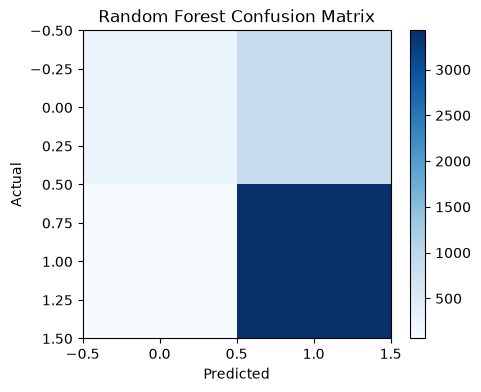

In [9]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

TASK 2: Implement Boosting Using XGBoost and LightGBM

Train XGBoost

In [10]:
xgb_model = XGBClassifier(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb_model.fit(X_train_tfidf, y_train)

xgb_pred = xgb_model.predict(X_test_tfidf)

Train LightGBM

In [11]:
lgb_model = LGBMClassifier(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

lgb_model.fit(X_train_tfidf, y_train)

lgb_pred = lgb_model.predict(X_test_tfidf)

Evaluate Boosting Models

In [12]:
boosting_models = {
    "XGBoost": xgb_pred,
    "LightGBM": lgb_pred
}

for name, pred in boosting_models.items():

    print("\n", name)

    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, zero_division=0))


 XGBoost
Accuracy: 0.7959051724137931
Precision: 0.7936691312384473
Recall: 0.9845227858985383
F1 Score: 0.8788537802225918

 LightGBM
Accuracy: 0.7965517241379311
Precision: 0.7953121373868647
Recall: 0.9822298652909143
F1 Score: 0.8789433187996922


Hyperparameter tuning using Grid search

In [13]:
param_grid = {
    'n_estimators': [30, 50],
    'max_depth': [3, 5],
    'learning_rate': [0.1]
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=2,
    scoring='accuracy',
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train_tfidf, y_train)

Fitting 2 folds for each of 4 candidates, totalling 8 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.1], 'max_depth': [3, 5], 'n_estimators': [30, 50]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py

best parameters

In [14]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50}
Best CV Accuracy: 0.7993101961629662


Evaluate Tuned XGBoost

In [15]:
best_xgb = grid_search.best_estimator_

best_xgb_pred = best_xgb.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, best_xgb_pred))
print("Precision:", precision_score(y_test, best_xgb_pred, zero_division=0))
print("Recall:", recall_score(y_test, best_xgb_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, best_xgb_pred, zero_division=0))

Accuracy: 0.8073275862068966
Precision: 0.8065201984408221
Recall: 0.9785038693035254
F1 Score: 0.8842268842268842


TASK 3: Implement Stacking Classifier

Create Base Models

In [16]:
base_models = [
    ('lr', LogisticRegression(max_iter=1000)),
    ('dt', DecisionTreeClassifier(max_depth=10, random_state=42)),
    ('svm', LinearSVC(random_state=42))
]

create staking classifier

In [17]:
stack_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=2,
    n_jobs=-1
)

train stacking model

In [18]:
stack_model.fit(X_train_tfidf, y_train)

stack_pred = stack_model.predict(X_test_tfidf)

evaluate stacking model

In [19]:
print("Stacking Classifier Results")

print("Accuracy:", accuracy_score(y_test, stack_pred))
print("Precision:", precision_score(y_test, stack_pred, zero_division=0))
print("Recall:", recall_score(y_test, stack_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, stack_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, stack_pred, zero_division=0))

Stacking Classifier Results
Accuracy: 0.8415948275862069
Precision: 0.8606600314300681
Recall: 0.941817139581542
F1 Score: 0.8994115231969344

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.54      0.63      1151
           1       0.86      0.94      0.90      3489

    accuracy                           0.84      4640
   macro avg       0.81      0.74      0.76      4640
weighted avg       0.83      0.84      0.83      4640



Train Individual Models